# 14. Reciprocal-Space Momentum Spectrum: $k_\parallel$ Excitation Distribution

## Physical Motivation & Learning Objectives
In diffraction gratings, momentum conservation dictates that transverse momentum is conserved modulo reciprocal lattice vectors:
$$\mathbf{k}_\parallel^{(m)} = \mathbf{k}_\parallel^{(0)} + m \frac{2\pi}{\Lambda} \hat{\mathbf{x}}$$
In this tutorial, we visualize transmitted plane-wave amplitudes in momentum space as a function of normalized in-plane wavevector $k_\parallel / k_0$ using `plotting.t_func_k_plot_1D`.


**Legacy example.** This notebook reproduces `simo_053-plotting_k_space_amps.py` from the original EMUstack. It uses that script's inputs unchanged; T, R and A then agree with legacy EMUstack to 5e-5 (checked in `benchmarks/parity/`, `examples/` version).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



## Simulation Setup


In [2]:
azi_angles = np.linspace(-89, 89, 91)
wavelengths = np.array([1600.0])
period = 700.0  # nm

light_list = [objects.Light(wavelengths[0], max_order_PWs=10, theta=p, phi=0.0) for p in azi_angles]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
absorber    = objects.ThinFilm(period, height_nm=10.0, material=materials.Material(1.0 + 0.05j), world_1d=True, loss=True)

grating = objects.NanoStruct(
    '1D_array', period, int(round(0.75 * period)),
    height_nm=2900.0,
    background=materials.Material(1.46),
    inclusion_a=materials.Material(3.61),
    loss=True, lc_bkg=0.005, plt_msh=False
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_abs = absorber.calc_modes(light)
    sim_grt = grating.calc_modes(light)
    stk = Stack((sim_sub, sim_abs, sim_grt, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

stacks_list = [simulate_stack(light) for light in light_list]


## $k$-Space Transmitted Order Spectrum


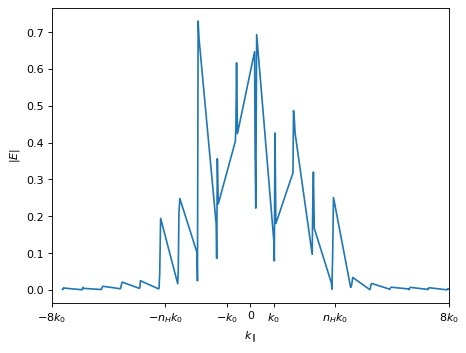

In [3]:
fig_k = plotting.t_func_k_plot_1D(stacks_list, save_pdf=False)
plt.show()


## Physical Interpretation
Diffracted orders with $|k_\parallel| < k_0$ represent propagating radiating waves inside the light cone, whereas orders with $|k_\parallel| > k_0$ decay evanescently away from the grating interfaces.
